# TROSY of a rotating ¹³CF₃ group

Coupled to its three fluorines, the ¹³C of a ¹³CF₃ group gives a 1:3:3:1
quartet whose lines relax at very different rates. The C–F dipoles
cross-correlate with each other and with the ¹³C shielding anisotropy, and
when the group rotates fast about its C₃ axis one line of the quartet
becomes much narrower than the ¹⁹F-decoupled line: a TROSY effect. This
guide models the rotation as axially symmetric rotational diffusion,
splits the relaxation of the ¹³C single-quantum block into its mechanisms
with `spynach.relaxation_pathways`, draws the block as a chord diagram, and
reads the linewidths of the quartet off the same six operators. Read the
[relaxation pathways guide](relaxation-pathways.ipynb) first. The companion
notebook is [`notebooks/cf3-trosy.ipynb`](cf3-trosy.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/cf3-trosy.ipynb)).

The parameters come from a set of Spinach scripts for the trifluoromethionine
of a protein: DFT tensors of Ac-L-trifluoromethionine-NH₂ (M06/cc-pVDZ,
GIAO, SMD water), made exactly C₃-symmetric, with the mean ¹J(CF) of
−255.7 Hz. The browser playground runs the same model
([`try.html#ex-cf3-trosy`](https://ajerschow.github.io/spynach/try.html#ex-cf3-trosy)),
with the field, the tumbling and rotation times, the raw or symmetrised
tensors and a second parameter set in its form.

Every Python block is executed by `tests/docs/`, in order and in one
namespace. The expressions need SymPy (the `symbolic` extra of the [install](https://ajerschow.github.io/spynach/#install)).

*Generated from [`docs/cf3-trosy.md`](../cf3-trosy.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Internal rotation as axial diffusion](#Internal-rotation-as-axial-diffusion)
2. [The group](#The-group)
3. [The ¹³C single-quantum block](#the-13c-single-quantum-block)
4. [The chord diagram](#The-chord-diagram)
5. [The quartet from six operators](#The-quartet-from-six-operators)
6. [What narrows the line](#What-narrows-the-line)
7. [Linewidths against the rotation time](#Linewidths-against-the-rotation-time)
8. [Checks](#Checks)

## Internal rotation as axial diffusion

The tumbling of the protein (correlation time `tau_c`) and the rotation of
the CF₃ group about its C₃ axis (correlation time `tau_int`) are modelled
together as rotational diffusion that is axially symmetric about C₃, the
model of Woessner. With `D_perp = 1/(6 tau_c)` and
`D_par = D_perp + 1/tau_int`, the component `m` of a tensor about the axis
decays at

    1/tau_m = 6 D_perp + m^2 (D_par - D_perp) = 1/tau_c + m^2/tau_int

so every spectral density `J(w)` of the rigid group splits into
`J_m(w) = tau_m / (1 + w^2 tau_m^2)` for `m = 0, 1, 2`, weighted by the
parts of the two tensors with that `m` (the module docstring of
`spynach.pathways` gives the formula). For a C–F dipole at the angle
`theta` to the axis the weights are Woessner's `(3 cos^2 theta - 1)^2 / 4`,
`3 sin^2 theta cos^2 theta` and `3 sin^4 theta / 4`. When the group rotates
fast (`tau_int << tau_c`), `J_1` and `J_2` are small and only the projections
of the tensors on C₃ relax the spins.

Spinach and Spynach take the diffusion axis along z of the molecular frame
and two correlation times `inter["tau_c"] = [[tau_par, tau_perp]]`, with
`tau = 1 / (6 D)`. Tensors and coordinates are therefore given in the C₃
frame, and `tau_par = 1 / (1/tau_c + 6/tau_int)`. `spynach.relaxation`
handles this numerically; `relaxation_pathways` gives the same rates with
the expressions in `J_0`, `J_1` and `J_2`.

## The group

In the C₃ frame (z from the carbon to the centroid of the fluorines, x along
the first C–F bond) the ¹³C shift anisotropy is axial, `delta_zz = −19.62`
ppm. The first fluorine carries the C₃-averaged ¹⁹F tensor, and the other two
its images under rotations by 120°. The C–F bonds are 1.335 Å long, at 68.54°
to the axis. The isotropic shifts are left out, so every spin is on
resonance, and the shift tensors are `delta = −sigma` of the DFT shieldings:

In [1]:
import dataclasses
import logging

import numpy as np

import spynach
from spynach.plotting import plot_pathways, plot_time_series

logging.getLogger("spynach").setLevel(logging.ERROR)  # the Redfield integrals below take long steps, as they should


def rotz(angle):
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1.0]])


def cf3_group(tau_int, tau_c=50e-9, magnet=18.8):
    """13CF3 of trifluoromethionine in its C3 frame, rotating about C3 with the correlation time tau_int (s)."""
    turns = [rotz(2 * np.pi * k / 3) for k in range(3)]
    fluorine = np.array([[-35.66, -0.92, -72.86], [-0.92, 17.48, 1.63], [-72.86, 1.63, 18.18]])  # ppm, site 1
    theta = np.radians(68.54)  # C-F bond against C3
    bond = 1.335 * np.array([np.sin(theta), 0, np.cos(theta)])  # Angstrom
    return spynach.create(
        {"isotopes": ["13C", "19F", "19F", "19F"], "magnet": magnet},
        {"zeeman": {"matrix": [np.diag([9.81, 9.81, -19.62])] + [R @ fluorine @ R.T for R in turns]},
         "coordinates": [[0, 0, 0]] + [R @ bond for R in turns],
         "coupling": {"scalar": [[0, -255.7, -255.7, -255.7], [0] * 4, [0] * 4, [0] * 4]},
         "relaxation": ["redfield"], "rlx_keep": "secular", "equilibrium": "zero",
         "tau_c": [[1 / (1 / tau_c + 6 / tau_int), tau_c]]},
    )


group = cf3_group(50e-12)

The field is 18.8 T (800 MHz), the protein tumbles with `tau_c = 50` ns and
the group rotates with `tau_int = 50` ps. The ¹⁹F–¹⁹F scalar coupling is
left out: between magnetically equivalent spins it changes nothing here.

## The ¹³C single-quantum block

Directly detected ¹³C magnetisation lives in the block of ¹³C coherence +1
and ¹⁹F coherence 0. `coherence` given as a dictionary per isotope selects
it. `max_per_group=3` and `max_order=4` admit the products of up to three
fluorine operators, which the analysis symmetrises over the group:
`C+FzFz` is `C+` times the sum of `FkzFlz` over the three pairs, and `C+F+F-`
is `C+` times the sum of `Fk+Fl-` over `k != l`. `resolve="interaction"`
names the mechanism classes by the elements as well as by the kinds, so that
the cross-correlation of the C–F dipoles with the ¹³C anisotropy,
`DD(CF)/CSA(C)`, is told apart from that of the F–F dipoles with the ¹⁹F
anisotropy, `DD(FF)/CSA(F)`. `DD(CF)/DD(CF')` is the cross-correlation
between two different C–F dipoles:

In [2]:
observed = {"coherence": {"13C": 1, "19F": 0}, "max_per_group": 3, "max_order": 4, "resolve": "interaction"}
pathways = spynach.relaxation_pathways(group, **observed)
print(pathways.labels)
print(pathways.classes)
print("tau_0, tau_1, tau_2 (ps):", [round(t * 1e12, 2) for t in pathways.correlation_times])
for link in pathways.links()[:5]:
    a, b = pathways.labels[link.source], pathways.labels[link.target]
    print(f"{a} <-> {b}: {link.rate:.2f} s^-1 from {', '.join(link.signature)}")

['C+', 'C+Fz', 'C+FzFz', 'C+F+F-', 'C+FzFzFz', 'C+FzF+F-']
['DD(CF)', 'DD(FF)', 'CSA(C)', 'CSA(F)', "DD(CF)/DD(CF')", "DD(FF)/DD(FF')", 'DD(CF)/CSA(C)', 'DD(FF)/CSA(F)', "CSA(F)/CSA(F')"]
tau_0, tau_1, tau_2 (ps): [50000.0, 49.95, 12.5]
C+Fz <-> C+FzFz: 22.25 s^-1 from DD(CF)/CSA(C), DD(FF)/CSA(F)
C+ <-> C+Fz: 19.32 s^-1 from DD(CF)/CSA(C)
C+FzFz <-> C+FzFzFz: 19.21 s^-1 from DD(CF)/CSA(C), DD(FF)/CSA(F)
C+ <-> C+FzFz: 17.41 s^-1 from DD(CF)/DD(CF')
C+Fz <-> C+FzFzFz: 17.39 s^-1 from DD(CF)/DD(CF'), DD(FF)/DD(FF')


Two classes drive the five strongest pathways; the other classes listed
add less than 0.2 s⁻¹. `DD(CF)/CSA(C)` links neighbours in the ladder `C+`,
`C+Fz`, `C+FzFz`, `C+FzFzFz` (and `C+F+F-` with `C+FzF+F-`), and
`DD(CF)/DD(CF')` links next-but-one neighbours. Their expressions:

In [3]:
print(pathways.expression("C+", "C+Fz", "DD(CF)/CSA(C)"))
print(pathways.expression("C+", "C+FzFz", "DD(CF)/DD(CF')"))

-b_CF*dsigma_C*omega_C*(0.138208*J_0(0) + 0.103656*J_0(omega_C))
b_CF**2*(0.0620337*J_0(0) + 0.0465253*J_0(omega_C) - 0.12048*J_1(0) - 0.0903603*J_1(omega_C) - 0.194913*J_2(0) - 0.146185*J_2(omega_C))


`DD(CF)/CSA(C)` has `J_0` terms only, because the ¹³C tensor is axial about
C₃. This cross-correlation therefore survives fast rotation whole, scaled by
`P2(cos theta)` of the C–F bonds. In `DD(CF)/DD(CF')` the `J_1` and `J_2`
weights are negative: two bonds 120° apart in azimuth correlate with
`cos(120 m) = −1/2` in those components. The symbols are those of the
pathways guide, `b_CF` the C–F dipolar coupling (rad/s),
`dsigma_C` the ¹³C shielding anisotropy and `omega_C` the ¹³C Larmor
frequency. The numbers are floating-point, since the DFT geometry is not
exact.

## The chord diagram

With `split=True` every class is a ribbon of its own, and `min_rate=0.5`
hides the pathways below 0.5 s⁻¹:

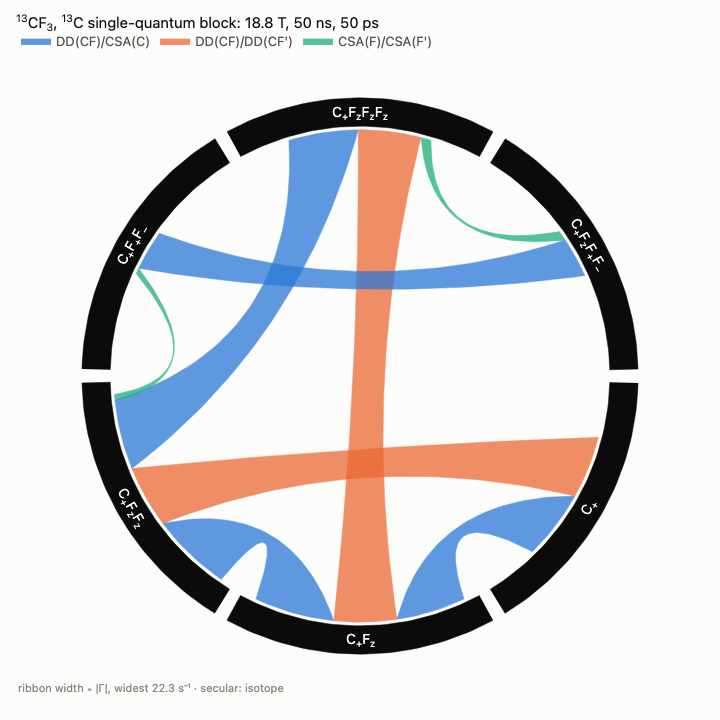

In [4]:
plot_pathways(pathways, split=True, min_rate=0.5,
              title="<sup>13</sup>CF<sub>3</sub>, <sup>13</sup>C single-quantum block: 18.8 T, 50 ns, 50 ps")

Hovering over a ribbon shows its rate and expression, and over an operator
its auto-relaxation rate. The weak `CSA(F)/CSA(F')` ribbons couple
`C+FzFz` and `C+FzFzFz` to the ¹⁹F zero-quantum operators `C+F+F-` and
`C+FzF+F-`.

## The quartet from six operators

For a C₃-symmetric group the six operators are a closed block: `C+` evolves
within it and nowhere else. Projecting Spynach's Hamiltonian, the
J coupling, onto the block (`pathways.states` gives the operators as
vectors of the `sphten-liouv` basis) and adding `-1j * Gamma` gives the
Liouvillian of the ¹³C signal. Its eigenvalues `lambda` are the line
components: the position is `−Re(lambda) / 2 pi`, and the full width at half
height is `R2 / pi`, with `R2 = −Im(lambda)`. The weight of each component
is its share of the signal of `C+`, read from the eigenvectors:

In [5]:
spin_system = spynach.basis(group, {"formalism": "sphten-liouv", "approximation": "none"})
V = pathways.states(spin_system)
H6 = V.conj() @ spynach.hamiltonian(spynach.assume(spin_system, "nmr")) @ V.T


def lines(rates):
    """Components of the 13C signal of C+: position (Hz), full width at half height (Hz), complex weight."""
    lam, modes = np.linalg.eig(H6 - 1j * rates)
    weights = modes[0] * np.linalg.solve(modes, np.eye(len(lam))[0])
    return sorted(zip(-lam.real / (2 * np.pi), -lam.imag / np.pi, weights), key=lambda line: line[0])


for position, width, weight in lines(pathways.rate_matrix()):
    print(f"{position:+8.1f} Hz   {width:6.2f} Hz   weight {weight.real:.3f}")
print(f"19F-decoupled line: {pathways.rate_matrix()[0, 0] / np.pi:.2f} Hz")

  -383.5 Hz     7.02 Hz   weight 0.125
  -127.9 Hz     2.73 Hz   weight 0.053
  -127.8 Hz     1.05 Hz   weight 0.322
  +127.8 Hz     8.16 Hz   weight 0.324
  +127.9 Hz     9.70 Hz   weight 0.051
  +383.5 Hz    28.26 Hz   weight 0.125
19F-decoupled line: 6.91 Hz


The lines sit at `−M_F · J(CF)` for the total ¹⁹F projection `M_F` of each
line. The inner lines, `M_F = ±1/2`, have two components each: one from the
fluorine states of total spin 3/2 and one from those of total spin 1/2.
At −127.8 Hz (`M_F = −1/2`) the main component is 1.05 Hz wide and carries
0.32 of the line's 0.375. The ¹⁹F-decoupled line is 6.91 Hz wide, and the
outer line at +383.5 Hz is 28.3 Hz wide. As a spectrum, with each component
a Lorentzian:

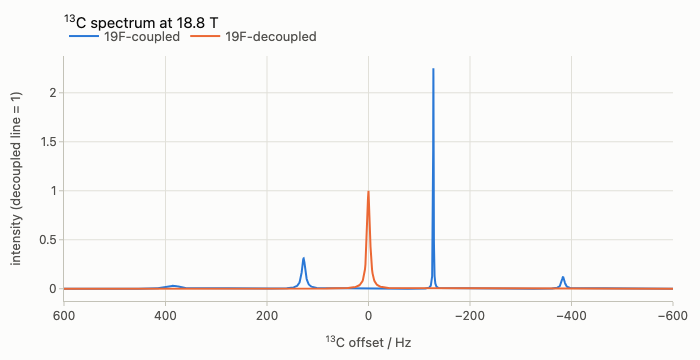

In [6]:
# a coarse axis, refined around every component so that the narrow line is drawn exactly
components = lines(pathways.rate_matrix())
axis = np.unique(np.concatenate([np.linspace(-600, 600, 1201)]
                                + [f + width * np.linspace(-5, 5, 101) for f, width, _ in components]))


def spectrum(components):
    return sum(np.real(w / (np.pi * width + 2j * np.pi * (axis - f))) for f, width, w in components)


decoupled = [(0.0, pathways.rate_matrix()[0, 0] / np.pi, 1.0)]
peak = spectrum(decoupled).max()
fig = plot_time_series(axis, [spectrum(components) / peak, spectrum(decoupled) / peak],
                       names=["19F-coupled", "19F-decoupled"], xlabel="<sup>13</sup>C offset / Hz",
                       ylabel="intensity (decoupled line = 1)", title="<sup>13</sup>C spectrum at 18.8 T")
fig.update_xaxes(autorange="reversed")

The narrow line is about twice as high as the decoupled line. It carries
3/8 of the signal, which is more than offset by its sixfold smaller width.

## What narrows the line

`rate_matrix(classes)` builds `Gamma` from some of the classes, so a
cross-correlation can be switched off to see what it does:

In [7]:
choices = {
    "all": pathways.classes,
    "without DD(CF)/CSA(C)": [c for c in pathways.classes if c != "DD(CF)/CSA(C)"],
    "without DD(CF)/DD(CF')": [c for c in pathways.classes if c != "DD(CF)/DD(CF')"],
    "no cross-correlation": [c for c in pathways.classes if "/" not in c],
}
for name, kept in choices.items():
    widths = [f"{width:6.2f}" for _, width, weight in lines(pathways.rate_matrix(kept)) if abs(weight) > 0.05]
    print(f"{name:>24}: {' '.join(widths)} Hz")

                     all:   7.02   2.73   1.05   8.16   9.70  28.26 Hz
   without DD(CF)/CSA(C):  17.67   6.28   4.60   4.61   6.15  17.60 Hz
  without DD(CF)/DD(CF'):  -2.58   4.63  11.68  18.66 Hz
    no cross-correlation:   8.04   8.03   8.03   8.04 Hz


Without `DD(CF)/CSA(C)` the quartet is symmetric: the two inner lines are
4.6 Hz wide, the outer ones 17.6 Hz. This cross-correlation makes the lines
of one sign of `M_F` narrow and those of the other broad, as the
dipole–CSA cross-correlation does in ¹⁵N TROSY. Without any
cross-correlation all four lines are about 8 Hz wide. Switching off
`DD(CF)/DD(CF')` alone gives a negative width, which is not physical. Three
dipoles that do not correlate with each other cannot all correlate with the
same ¹³C anisotropy, so `Gamma` without that one class is not positive.
`DD(CF)/DD(CF')` goes with `DD(CF)/CSA(C)` or not at all.

## Linewidths against the rotation time

The coefficients of the analysis do not depend on the correlation times, so
`dataclasses.replace(pathways, tau_c=...)` gives the relaxation matrix at
another rotation time without building it again. Below, the width of the
strongest component of each line, from 1 ps to 10 ns:

1 ps: [27.107  7.142  0.042  5.806  6.787] Hz;  10 ns: [27.26 13.59  6.52  6.05 11.52] Hz


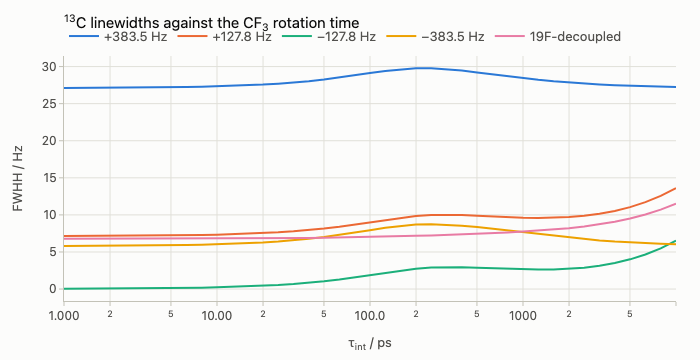

In [8]:
def widths_at(tau_int):
    """Width (Hz) of the strongest component of each quartet line, and of the decoupled line."""
    rates = dataclasses.replace(pathways, tau_c=(1 / (1 / 50e-9 + 6 / tau_int), 50e-9)).rate_matrix()
    strongest = {}
    for position, width, weight in lines(rates):
        key = round(position)
        if abs(weight) > strongest.get(key, (0.0, 0.0))[0]:
            strongest[key] = (abs(weight), width)
    return [strongest[key][1] for key in sorted(strongest, reverse=True)] + [rates[0, 0] / np.pi]


grid = np.logspace(-12, -8, 41)
widths = np.array([widths_at(t) for t in grid]).T
print("1 ps:", np.round(widths[:, 0], 3), "Hz;  10 ns:", np.round(widths[:, -1], 2), "Hz")
fig = plot_time_series(grid / 1e-12, widths, names=["+383.5 Hz", "+127.8 Hz", "−127.8 Hz", "−383.5 Hz", "19F-decoupled"],
                       xlabel="τ<sub>int</sub> / ps", ylabel="FWHH / Hz",
                       title="<sup>13</sup>C linewidths against the CF<sub>3</sub> rotation time")
fig.update_xaxes(type="log", range=[0, 4])  # a log axis takes its range in decades: 1 ps to 10 ns

At 1 ps the line at −127.8 Hz is 0.042 Hz wide, 160 times narrower than
the decoupled line. At 10 ns, when the group barely rotates during the
tumbling, it is 6.5 Hz wide. The outer line at +383.5 Hz stays broad
throughout. In a rigid group the narrow line is the outer one at
−383.5 Hz. Rotation moves the narrowing to the inner line, because only the
projections on C₃ survive it.

## Checks

The six operators against Spynach's own Liouvillian: `spynach.reduce`
finds the states that `C+` reaches under `H + iR`, with `R` from
`spynach.relaxation` (the numerical Redfield integral with axial
diffusion), and the six-operator modes are among its eigenvalues:

In [9]:
L = spynach.hamiltonian(spynach.assume(spin_system, "nmr")) + 1j * spynach.relaxation(spin_system)
P = np.hstack([p.toarray() for p in spynach.reduce(spin_system, L, spynach.state(spin_system, "L+", "13C"))])
exact = np.linalg.eigvals(P.conj().T @ L @ P)
six = np.linalg.eigvals(H6 - 1j * pathways.rate_matrix())
print(f"{P.shape[1]} states reached from C+; largest distance of a six-operator mode from the exact ones: "
      f"{max(np.abs(exact - mode).min() for mode in six):.1e} rad/s")

20 states reached from C+; largest distance of a six-operator mode from the exact ones: 1.3e-04 rad/s


The distance comes from the truncation of the numerical integral
(`tols.rlx_integration`). `tests/unit/test_pathways.py` makes the same check,
compares the rates with `spynach.relaxation` for every mechanism under axial
diffusion, and checks Woessner's weights symbolically for a bond
perpendicular to the axis.

Without the C₃ symmetrisation each fluorine keeps its own DFT tensor. The six
operators are then no longer an exact block, and the playground computes the
lines from the full Liouvillian. Even so, the widths from the six operators
agree with it to 0.1%. With those raw tensors, Spynach reproduces the
linewidths of the original Spinach scripts (the same diffusion model) to
1e-4 relative, from 1 ps to 10 ns of rotation time at 18.8 T. At most other
fields, Spinach 2.13's `rlx_keep = "secular"` drops secular elements of `R`
by comparing Zeeman frequencies for exact floating-point equality. Spynach
compares them to within rounding; see
[Retention policies](relaxation.ipynb#Retention-policies-and-dynamic-frequency-shifts).